In [36]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_squared_error

import matplotlib.pyplot as plt

df = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

Pearson correlation was used to choose the best feature to predict GameWeight as it's linear.

In [25]:
print(df.corr(numeric_only=True, method="pearson")['GameWeight'].sort_values(key=abs, ascending=False).head(10))

GameWeight           1.000000
AvgPlaytime_log      0.716753
AgeRec               0.634089
Cat:War              0.451530
NumWant_log          0.417958
Cat:Strategy         0.299984
MaxPlayers_log      -0.255949
NumWant              0.248581
NumExpansions_log    0.240796
Cat:Childrens       -0.220480
Name: GameWeight, dtype: float64


In [26]:
X = df[['AvgPlaytime_log']].copy()
y = df['GameWeight'].copy()

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [28]:
lin_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [29]:
lin_pipe.fit(X_train, y_train)
y_pred = lin_pipe.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Baseline LinearRegression")
print(f"R^2  : {r2:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"MAE  : {mae:.3f}")

Baseline LinearRegression
R^2  : 0.518
RMSE : 0.553
MAE  : 0.432


Baseline Linear Regression shows moderate fit (R² = 0.518), with RMSE = 0.553 and MAE = 0.432, meaning it explains about 52% of the variance but still has fairly large average prediction error.

In [30]:
coef = lin_pipe.named_steps["model"].coef_[0]
intercept = lin_pipe.named_steps["model"].intercept_
print(f"Model (scaled X): y = {coef:.4f}*AvgPlaytime_log + {intercept:.4f}")

Model (scaled X): y = 0.5720*AvgPlaytime_log + 2.0410


In [33]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

param_grid = [
    {
        "model": [Ridge()],
        "model__alpha": np.logspace(-6, 6, 25),
        "model__fit_intercept": [True, False],
        "model__tol": [1e-6, 1e-5, 1e-4, 1e-3] ,
        "model__solver": ["auto"],
    },
    {
        "model": [Lasso(max_iter=100000)],
        "model__alpha": np.logspace(-2, 2, 41),
        "model__fit_intercept": [True, False],
        "model__tol": [1e-5, 1e-4, 1e-3],
        "model__selection": ["cyclic", "random"],
    },
    {
        "model": [ElasticNet(max_iter=100000)],
        "model__alpha": np.logspace(-2, 2, 41),
        "model__l1_ratio": [0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 0.95],
        "model__fit_intercept": [True, False],
        "model__tol": [1e-5, 1e-4, 1e-3],
        "model__selection": ["cyclic", "random"],
    }
]


cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    cv=cv,
    scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
    refit="rmse",
    n_jobs=-1,
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_.named_steps["model"]
best_i = grid.best_index_

print("\nBest Model:", best_model.__class__.__name__)
print("Best Params:", grid.best_params_)
print("Best CV RMSE:", round(-grid.best_score_, 3))
print("CV R^2 at best RMSE:", round(grid.cv_results_["mean_test_r2"][best_i], 3))


Best Model: Ridge
Best Params: {'model': Ridge(), 'model__alpha': np.float64(1e-06), 'model__fit_intercept': True, 'model__solver': 'auto', 'model__tol': 1e-06}
Best CV RMSE: 0.559
CV R^2 at best RMSE: 0.511


Ridge is selected again as the best regularized linear model, but with alpha ≈ 1e-6 (effectively no regularization), which explains why performance is essentially the same as plain Linear Regression: CV RMSE = 0.559 and CV R² ≈ 0.511, indicating only a modest fit and limited benefit from regularization in this setup.

In [37]:
y_pred = grid.best_estimator_.predict(X_test)

rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
mae_test = mean_absolute_error(y_test, y_pred)

print("\nTest Performance")
print(f"R^2  : {r2_score(y_test, y_pred):.3f}")
print(f"RMSE : {rmse_test:.3f}")
print(f"MAE  : {mae_test:.3f}")


Test Performance
R^2  : 0.518
RMSE : 0.553
MAE  : 0.432


On the test set, the selected Ridge model matches the baseline results: R² = 0.518, RMSE = 0.553, and MAE = 0.432, indicating moderate predictive power with no meaningful gain from regularization (consistent with the near-zero alpha).

In [39]:
best_est = grid.best_estimator_
best_model = best_est.named_steps["model"]

coef = best_model.coef_[0]
intercept = best_model.intercept_

print(f"Best Model (scaled X): GameWeight =  {intercept:.4f} + {coef:.4f}*AvgPlaytime_log")


Best Model (scaled X): GameWeight =  2.0410 + 0.5720*AvgPlaytime_log


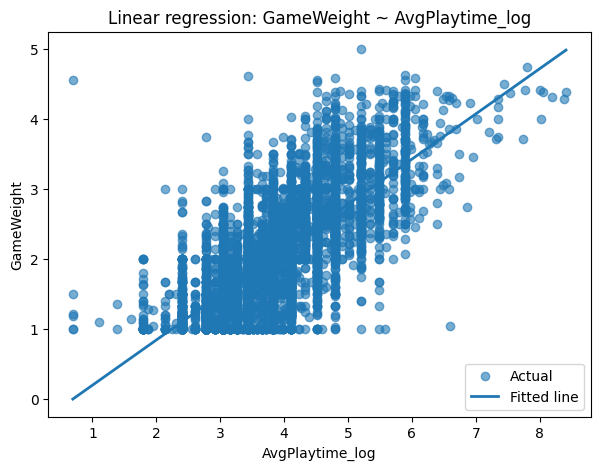

In [40]:
best_est = grid.best_estimator_
model_name = best_est.named_steps["model"].__class__.__name__

y_pred = best_est.predict(X_test)

plt.figure(figsize=(7,5))
plt.scatter(X_test['AvgPlaytime_log'], y_test, alpha=0.6, label="Actual")
# draw a line over sorted X for clean plot
x_line = np.linspace(X_test['AvgPlaytime_log'].min(), X_test['AvgPlaytime_log'].max(), 200).reshape(-1,1)
y_line = lin_pipe.predict(pd.DataFrame(x_line, columns=['AvgPlaytime_log']))
plt.plot(x_line, y_line, linewidth=2, label="Fitted line")
plt.xlabel("AvgPlaytime_log")
plt.ylabel("GameWeight")
plt.title("Linear regression: GameWeight ~ AvgPlaytime_log")
plt.legend()
plt.show()

The points are widely scattered around the fitted line (especially in the mid-range), indicating AvgPlaytime_log alone explains only part of the variation in GameWeight and tends to be less accurate at the extremes.

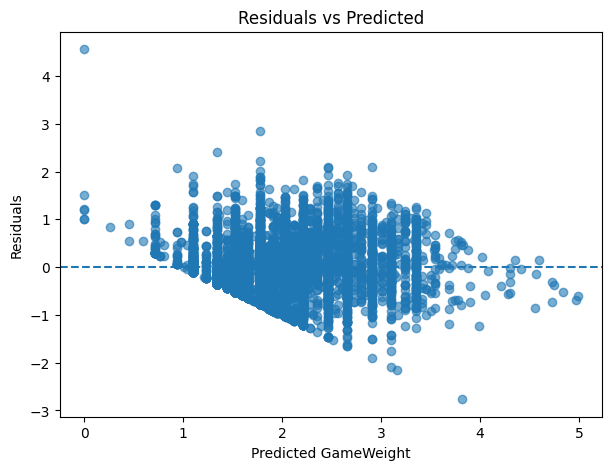

In [41]:
best_est = grid.best_estimator_
model_name = best_est.named_steps["model"].__class__.__name__

y_pred = best_est.predict(X_test)

resid = y_test - y_pred
plt.figure(figsize=(7,5))
plt.scatter(y_pred, resid, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted GameWeight")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.show()

The residual plot shows residuals are roughly centered around 0, but there’s a clear downward trend: the model tends to underpredict at low predicted GameWeight (positive residuals) and overpredict at higher predicted values (negative residuals). The widening spread and a few large outliers suggest the 1-feature linear model can’t capture all the variability, especially across the range.